<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/lab-009-mnist.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 009 — Regression and cross-entropy on MNIST

This notebook follows the MNIST example of Chapter 2 in detail. MNIST (Modified National Institute of Standards and Technology database) is a collection
of images of handwritten digits, and the same feed-forward network is trained on it twice, in two different formulations of the task.

The first formulation, model A, treats classification as regression with a single output node (Section *Image Classification with a Single Output Node*
of the chapter). The flattened image of $784$ pixels goes through one hidden layer of $21$ sigmoid nodes (as in the chapter) to **one** sigmoid output
$\bar y\in(0,1)$. The network is trained with the mean squared error (MSE) to reproduce the digit divided by $10$, and the prediction is $10\,\bar y$ rounded
to an integer. The second formulation, model B, is classification with ten output nodes and the categorical cross-entropy (Section *Multiclass
Classification and Categorical Cross-Entropy*). It has the same hidden layer (784 → 21 sigmoid nodes), but $10$ outputs, turned into probabilities by the
softmax and trained with the cross-entropy against one-hot labels.

> Both networks have the *same* hidden layer (784 → 21 sigmoid nodes, about $16\,500$ parameters), the same data, the same optimiser,
> the same number of epochs. They differ only in the output layer and the **loss function**. The single-output regression recognises about $65\%$ of the test
> digits, the ten-output cross-entropy network about $95\%$ (the chapter reports $56\%$ and $95\%$). The difference comes from how the task is posed:
> the output layer and the loss together. Exercise 2 shows that the ten outputs account for most of the gain (ten sigmoid outputs trained with the MSE
> already reach about $94\%$).

Nothing is hidden in a library call. We download the **original MNIST files** and decode their binary format with NumPy, without `torchvision.datasets`
(Section 1), look at the data (Section 2), and **flatten**, **standardise** and **split** the images into training, validation and test sets with a few
lines of NumPy (Section 3). The training set is then **cut into mini-batches** with our own function, and we check that PyTorch's `Dataset` and
`DataLoader` produce exactly the same batches (Section 4). With these pieces we write the complete **training loops** of both models, record their learning
curves and evaluate them with **confusion matrices** (Box 2.11) in Sections 5 and 6, compare them in Section 7, and test the conclusions in five exercises.

The whole notebook runs on a CPU (central processing unit) in a few minutes.

> To run this notebook in Google Colab, proceed as follows.
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `torch`) are pre-installed in Colab; no `pip install` required.
> 4. The data (about 11 MB) are downloaded once into the folder `data/MNIST_raw` in the current working directory (in Colab: `/content`, which is cleared when the runtime is recycled).
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, gzip, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)                    # fixes the random initial parameters
rng = np.random.default_rng(0)          # NumPy random generator, used for the train/validation split
print("PyTorch", torch.__version__, "  NumPy", np.__version__)

PyTorch 2.9.0+cpu   NumPy 2.1.3


<hr/>
## 1. The original MNIST files

### 1.1 Download
MNIST is distributed as four compressed files (`.gz`): images and labels, each for the training part ($60\,000$ images) and the test part ($10\,000$ images).
Libraries such as `torchvision` or `keras` download exactly these files and decode them for you. Here we do both steps ourselves.

`urllib.request.urlretrieve(url, path)` downloads a file from the internet and saves it on disk. The data set was introduced by Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, *Gradient-based learning applied to document recognition*, Proc. IEEE **86**, 2278–2324 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791); its original web page, <http://yann.lecun.com/exdb/mnist/>, no longer serves the files
reliably, so we use two public copies (*mirrors*) and take the first one that works. A file that is already on disk is not downloaded again.

In [2]:
DATA_DIR = "data/MNIST_raw"
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/",          # copy used by torchvision
           "https://storage.googleapis.com/cvdf-datasets/mnist/"]     # copy used by tensorflow
FILES = {"train_images": "train-images-idx3-ubyte.gz",
         "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images":  "t10k-images-idx3-ubyte.gz",
         "test_labels":  "t10k-labels-idx1-ubyte.gz"}

def download(filename):
    # Download one MNIST file into DATA_DIR (only if it is not there yet) and return its path.
    path = os.path.join(DATA_DIR, filename)
    if os.path.exists(path):
        return path
    os.makedirs(DATA_DIR, exist_ok=True)
    for mirror in MIRRORS:
        try:
            urllib.request.urlretrieve(mirror + filename, path)
            return path
        except Exception as err:
            print(f"  {mirror} failed: {err}")
            if os.path.exists(path):
                os.remove(path)                 # remove a partially downloaded file
    raise RuntimeError(f"could not download {filename}")

paths = {key: download(name) for key, name in FILES.items()}
for key, path in paths.items():
    print(f"{key:13s} {path:45s} {os.path.getsize(path) / 1e6:5.2f} MB")

train_images  data/MNIST_raw/train-images-idx3-ubyte.gz      9.91 MB
train_labels  data/MNIST_raw/train-labels-idx1-ubyte.gz      0.03 MB
test_images   data/MNIST_raw/t10k-images-idx3-ubyte.gz       1.65 MB
test_labels   data/MNIST_raw/t10k-labels-idx1-ubyte.gz       0.00 MB


### 1.2 The IDX file format
After decompression each file is a sequence of bytes (`ubyte` = unsigned byte, an integer $0\dots255$) in the very simple **IDX format**:

| bytes | content |
|---|---|
| 0–1 | always `0, 0` |
| 2 | data type; `8` (hex `0x08`) means unsigned bytes |
| 3 | number of dimensions $d$: `3` for images (number, rows, columns), `1` for labels |
| 4 … $4+4d-1$ | the $d$ sizes, each a 4-byte integer, most significant byte first (*big-endian*) |
| then | the data, one byte per pixel or label, row after row |

`gzip.open` decompresses on the fly. We read the first 16 bytes of the training images:

In [3]:
with gzip.open(paths["train_images"], "rb") as f:
    header = f.read(16)                                       # 4 bytes "magic number" + 3 sizes of 4 bytes
print("first 16 bytes:", list(header))

sizes = np.frombuffer(header, dtype=">i4")                     # ">i4" = big-endian 4-byte integer
print("as four big-endian integers:", sizes)
print("data type byte:", header[2], " number of dimensions:", header[3])

first 16 bytes: [0, 0, 8, 3, 0, 0, 234, 96, 0, 0, 0, 28, 0, 0, 0, 28]
as four big-endian integers: [ 2051 60000    28    28]
data type byte: 8  number of dimensions: 3


The four integers are $2051$ (the "magic number" $=$ `0x00000803`: data type `08`, $3$ dimensions), $60\,000$ images, $28$ rows and $28$ columns.
For example, $60\,000 = 0\cdot256^3 + 0\cdot256^2 + 234\cdot256 + 96$, which are bytes 4–7 above.

A complete reader is a few lines. `np.frombuffer` interprets raw bytes as an array without copying; `offset` skips the header.

In [4]:
def read_idx(path):
    # Read an IDX file (gzip-compressed) into a NumPy array of unsigned bytes.
    with gzip.open(path, "rb") as f:
        raw = f.read()
    assert raw[0] == 0 and raw[1] == 0 and raw[2] == 0x08, "not an IDX file of unsigned bytes"
    n_dims = raw[3]
    shape = np.frombuffer(raw, dtype=">i4", count=n_dims, offset=4)          # the d sizes
    data = np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * n_dims)        # all the rest
    return data.reshape(shape)

X_train_full = read_idx(paths["train_images"])
y_train_full = read_idx(paths["train_labels"])
X_test_raw   = read_idx(paths["test_images"])
y_test_raw   = read_idx(paths["test_labels"])

for name, a in [("X_train_full", X_train_full), ("y_train_full", y_train_full), ("X_test_raw", X_test_raw), ("y_test_raw", y_test_raw)]:
    print(f"{name:13s} shape {str(a.shape):16s} dtype {a.dtype}   values {a.min()} ... {a.max()}")
print("first 20 training labels:", y_train_full[:20])

X_train_full  shape (60000, 28, 28)  dtype uint8   values 0 ... 255
y_train_full  shape (60000,)         dtype uint8   values 0 ... 9
X_test_raw    shape (10000, 28, 28)  dtype uint8   values 0 ... 255
y_test_raw    shape (10000,)         dtype uint8   values 0 ... 9
first 20 training labels: [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]


That is the whole data set: an array of $60\,000$ images $28\times 28$ with integer pixel values $0$ (background) to $255$ (ink), the corresponding labels
$0\dots9$, and the same for the $10\,000$ test images. Everything that follows works with these NumPy arrays.

<hr/>
## 2. A look at the data

### 2.1 Examples of every class
`imshow` draws a 2D array as an image; the colour map `"gray_r"` shows $0$ as white and $255$ as black, as on paper.

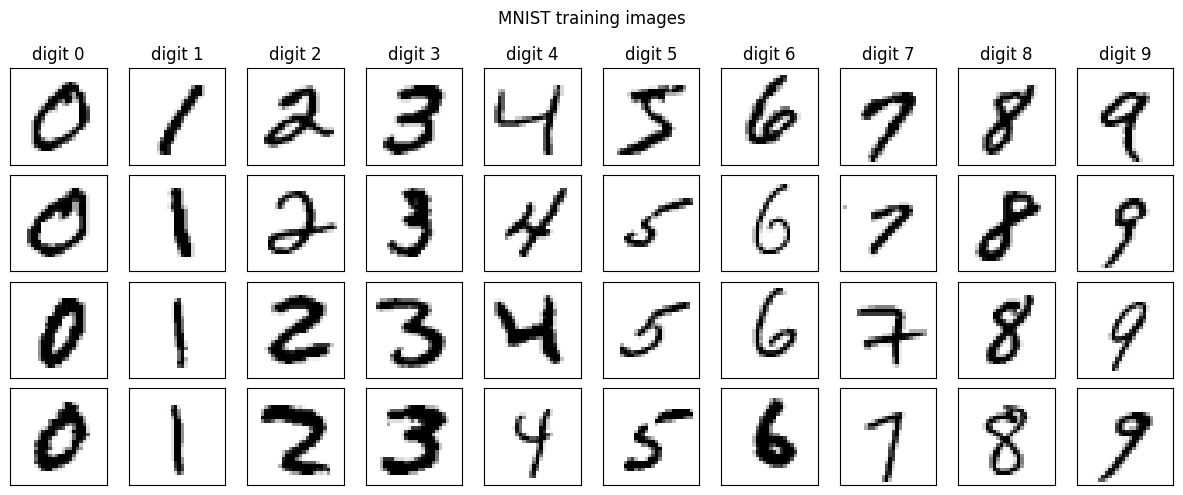

In [5]:
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for k in range(10):
    positions = np.flatnonzero(y_train_full == k)[:4]         # first four training images with label k
    for row, p in enumerate(positions):
        ax = axes[row, k]
        ax.imshow(X_train_full[p], cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
    axes[0, k].set_title(f"digit {k}")
fig.suptitle("MNIST training images")
fig.tight_layout(); plt.show()

### 2.2 Images per class
`np.bincount(y, minlength=10)` counts how often each of the values $0,\dots,9$ occurs.

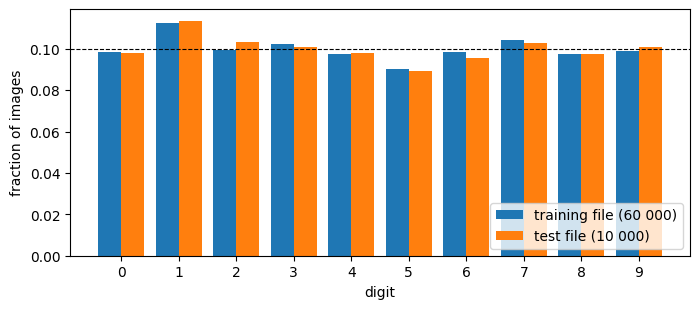

training counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
test counts    : [ 980 1135 1032 1010  982  892  958 1028  974 1009]


In [6]:
counts_train = np.bincount(y_train_full, minlength=10)
counts_test = np.bincount(y_test_raw, minlength=10)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(np.arange(10) - 0.2, counts_train / counts_train.sum(), width=0.4, label="training file (60 000)")
ax.bar(np.arange(10) + 0.2, counts_test / counts_test.sum(), width=0.4, label="test file (10 000)")
ax.axhline(0.1, color="k", lw=0.8, ls="--")
ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("fraction of images"); ax.legend(loc="lower right")
plt.show()
print("training counts:", counts_train)
print("test counts    :", counts_test)

The classes are nearly balanced (between about $9\%$ and $11\%$ each), so a model that always answers the same digit would be right in only about $10\%$ of
the cases, and so would random guessing. Any useful model must do much better than $10\%$.

### 2.3 The mean image of every class
Averaging all training images of one digit shows the "typical" shape and how much it varies (blurred regions = places where different writers put the
ink differently).

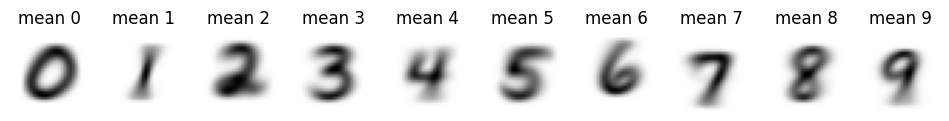

In [7]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k in range(10):
    axes[k].imshow(X_train_full[y_train_full == k].mean(axis=0), cmap="gray_r")
    axes[k].set_title(f"mean {k}"); axes[k].axis("off")
plt.show()

### 2.4 Flattening
The networks of this notebook (dense / fully connected) take a **vector** as input. A $28\times28$ image becomes a vector of $m = 784$ numbers by writing
the rows one after another: pixel $(i, j)$ (row $i$, column $j$) goes to position $28\,i + j$. This is what `reshape` does (NumPy and PyTorch store arrays
row by row, so no data are moved).

pixel (row 6, column 14) = 253,   vector element 182 = 253


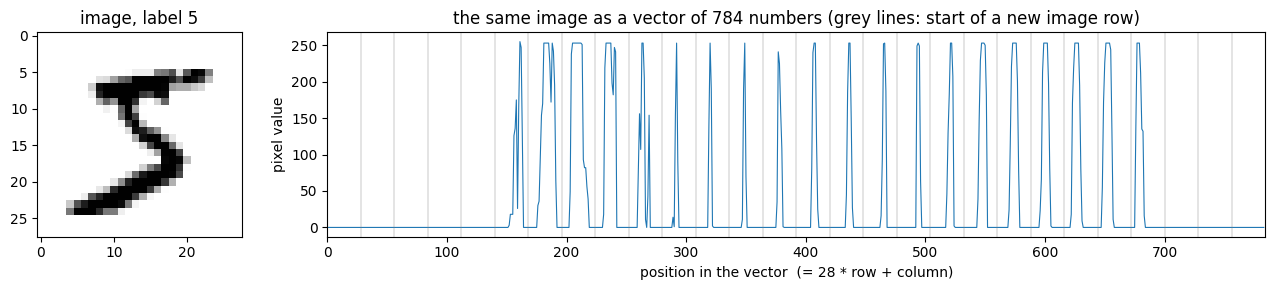

In [8]:
img = X_train_full[0]                         # one image, shape (28, 28)
vec = img.reshape(784)                        # the same numbers, shape (784,)
i, j = 6, 14
print(f"pixel (row {i}, column {j}) = {img[i, j]},   vector element {28 * i + j} = {vec[28 * i + j]}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw={"width_ratios": [1, 4]})
axes[0].imshow(img, cmap="gray_r"); axes[0].set_title(f"image, label {y_train_full[0]}")
axes[1].plot(vec, lw=0.8)
for r in range(1, 28):
    axes[1].axvline(28 * r, color="grey", lw=0.3)              # boundaries between image rows
axes[1].set_xlim(0, 784); axes[1].set_xlabel("position in the vector  (= 28 * row + column)"); axes[1].set_ylabel("pixel value")
axes[1].set_title("the same image as a vector of 784 numbers (grey lines: start of a new image row)")
fig.tight_layout(); plt.show()

Each bump in the right panel is one image row crossing the stroke. The network sees only this list of $784$ numbers: it does not know which pixels are
neighbours. (Convolutional networks, discussed later in Chapter 2, use the 2D arrangement.)

<hr/>
## 3. Splitting the data set (Box 2.10)

### 3.1 Training, validation and test sets
The three sets have different roles. The **training set** is used to change the parameters (gradient descent). The **validation set** is used *during*
development: to watch for overfitting and to choose settings (number of epochs, learning rate, architecture). The **test set** is used **once**, at the
very end, to report the final quality; if it were used to choose settings, it would no longer measure performance on new data. For teaching purposes the
analyses and exercises below also look at the test set; in a real project such comparisons would be made on the validation set.

The MNIST test file is our test set. The $60\,000$ training images are split at random into $50\,000$ for training and $10\,000$ for validation.
The split must be **random**: a data file may be ordered (by class, by writer, by date of collection), and the first images of a file need not be
representative of the rest. `rng.permutation(n)` returns the numbers $0,\dots,n-1$ in a random order; the first $50\,000$ of them select the training images.

In [9]:
n_full = len(X_train_full)
perm = rng.permutation(n_full)                     # a random order of 0, ..., 59999
idx_train, idx_val = perm[:50_000], perm[50_000:]
print("first 10 entries of the permutation:", perm[:10])
print("training indices:", len(idx_train), "  validation indices:", len(idx_val))
print("common indices:", len(np.intersect1d(idx_train, idx_val)),
      "  together they cover all images:", np.array_equal(np.sort(np.concatenate([idx_train, idx_val])), np.arange(n_full)))

X_tr_img, y_tr_np = X_train_full[idx_train], y_train_full[idx_train]
X_va_img, y_va_np = X_train_full[idx_val],   y_train_full[idx_val]
X_te_img, y_te_np = X_test_raw,              y_test_raw

first 10 entries of the permutation: [ 4013 23840 29603 43011 58703  2290 55984 52800 34316 12976]
training indices: 50000   validation indices: 10000
common indices: 0   together they cover all images: True


Indexing a NumPy array with an array of indices (`X_train_full[idx_train]`) picks the rows in that order. No image is in both sets, and together they use
every image exactly once. The random split gives training and validation sets with the same class proportions, which also match the test file:

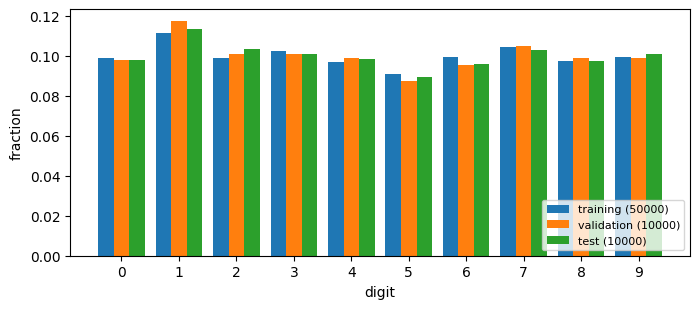

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for shift, (name, y) in zip([-0.27, 0, 0.27], [("training", y_tr_np), ("validation", y_va_np), ("test", y_te_np)]):
    ax.bar(np.arange(10) + shift, np.bincount(y, minlength=10) / len(y), width=0.27, label=f"{name} ({len(y)})")
ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("fraction"); ax.legend(loc="lower right", fontsize=8)
plt.show()

### 3.2 Flattening and standardisation
As in the chapter, the input vectors are **standardised** to mean $0$ and standard deviation $1$:
$$\mathbf x \;\leftarrow\; \frac{\mathbf x - \mu}{s},$$
with one number $\mu$ (mean) and one number $s$ (standard deviation) computed over all pixels of all **training** images. Inputs of order one keep the
pre-activations $\mathbf W\mathbf x + \mathbf b$ in the range where the sigmoid is not flat, which makes gradient descent work well.

$\mu$ and $s$ are computed from the training set **only** and then applied unchanged to validation and test data. Using statistics of the test set would let
information about the test data leak into the model (*data leakage*); in a real application the test data are not even available when the model is built.

Finally the arrays are converted to PyTorch tensors: inputs as `float32` (the default type of PyTorch parameters), labels as `int64` (the type
PyTorch expects for class indices).

In [11]:
def flatten(images):
    # (N, 28, 28) uint8  ->  (N, 784) float32
    return images.reshape(len(images), -1).astype(np.float32)

X_tr_flat, X_va_flat, X_te_flat = flatten(X_tr_img), flatten(X_va_img), flatten(X_te_img)
mu, s = X_tr_flat.mean(), X_tr_flat.std()          # from the TRAINING set only
print(f"training-set pixel statistics: mean {mu:.2f}, std {s:.2f}  (on the 0..255 scale)")

X_tr = torch.from_numpy((X_tr_flat - mu) / s)
X_va = torch.from_numpy((X_va_flat - mu) / s)
X_te = torch.from_numpy((X_te_flat - mu) / s)
y_tr = torch.from_numpy(y_tr_np.astype(np.int64))
y_va = torch.from_numpy(y_va_np.astype(np.int64))
y_te = torch.from_numpy(y_te_np.astype(np.int64))

for name, X, y in [("train", X_tr, y_tr), ("val", X_va, y_va), ("test", X_te, y_te)]:
    print(f"{name:5s}  X {tuple(X.shape)} {X.dtype}  mean {X.mean():+.3f} std {X.std():.3f}   y {tuple(y.shape)} {y.dtype}")

training-set pixel statistics: mean 33.33, std 78.57  (on the 0..255 scale)
train  X (50000, 784) torch.float32  mean +0.000 std 1.000   y (50000,) torch.int64
val    X (10000, 784) torch.float32  mean -0.001 std 1.000   y (10000,) torch.int64
test   X (10000, 784) torch.float32  mean +0.006 std 1.008   y (10000,) torch.int64


The training inputs have mean $0$ and standard deviation $1$ by construction; validation and test inputs are close to that but not exactly, since they
were transformed with the training statistics. The background pixels ($0$) become $-\mu/s \approx -0.42$, full ink ($255$) becomes about $2.8$.

<hr/>
## 4. Mini-batches

### 4.1 Mini-batches from a random permutation
The gradient of the loss is an average over images. Computing it over all $50\,000$ images before every parameter update (*full-batch gradient descent*,
as in the chapter's equations) is expensive. Instead, in every **epoch** (one pass over the training set):

1. the training indices are put in a new random order,
2. the order is cut into consecutive pieces of `batch_size` indices (**mini-batches**),
3. for each mini-batch the loss and its gradient are computed on these images only, and the parameters are updated.

Every image is used exactly once per epoch; one epoch makes $\lceil 50\,000/B\rceil$ updates (with $B$ the batch size). The gradient of a mini-batch is a noisy estimate
of the full gradient (*stochastic* gradient descent), but many cheap noisy steps are much faster than a few exact ones.

The function below produces the index arrays of the mini-batches. It is a Python **generator**: `yield` hands out one value and pauses the function
until the next value is requested by the `for` loop, so the batches are produced one at a time.

In [12]:
def batch_indices(n, batch_size, shuffle=True, generator=None):
    # Yield index tensors of consecutive mini-batches covering 0, ..., n-1 once.
    order = torch.randperm(n, generator=generator) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        yield order[start:start + batch_size]          # the last batch may be shorter

batch_size = 64
batches = list(batch_indices(len(X_tr), batch_size, generator=torch.Generator().manual_seed(0)))
print("number of mini-batches per epoch:", len(batches), "  ( = ceil(50000 / 64) =", int(np.ceil(50000 / 64)), ")")
print("sizes of the first three and of the last batch:", [len(b) for b in batches[:3]], len(batches[-1]))
print("first batch indices:", batches[0][:10].tolist(), "...")
all_used = torch.sort(torch.cat(batches)).values
print("every training image used exactly once:", torch.equal(all_used, torch.arange(len(X_tr))))

number of mini-batches per epoch: 782   ( = ceil(50000 / 64) = 782 )
sizes of the first three and of the last batch: [64, 64, 64] 16
first batch indices: [36044, 49165, 37807, 11341, 6091, 16904, 36293, 28026, 24681, 17849] ...
every training image used exactly once: True


$50\,000 = 781\cdot 64 + 16$, hence $782$ batches, the last one with $16$ images. A batch of data is then `X_tr[idx], y_tr[idx]`: a matrix
$X_i\in\mathbb R^{64\times784}$ (one image per row, as in the chapter's feed-forward pass) and a vector of $64$ labels.

one mini-batch: inputs (64, 784)   labels (64,)


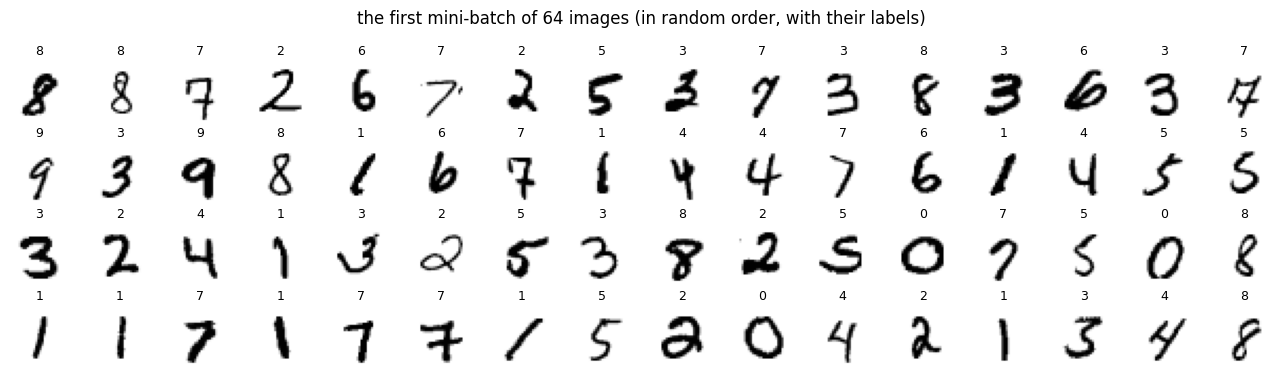

In [13]:
idx = batches[0]
xb, yb = X_tr[idx], y_tr[idx]
print("one mini-batch: inputs", tuple(xb.shape), "  labels", tuple(yb.shape))

fig, axes = plt.subplots(4, 16, figsize=(13, 3.8))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(x.reshape(28, 28), cmap="gray_r")        # back to 28 x 28 for display only
    ax.set_title(str(y.item()), fontsize=9); ax.axis("off")
fig.suptitle("the first mini-batch of 64 images (in random order, with their labels)")
fig.tight_layout(); plt.show()

### 4.2 `Dataset` and `DataLoader`
PyTorch packages these two steps into two classes from `torch.utils.data`. A **`Dataset`** knows how many samples there are (`__len__`) and returns sample
number `i` (`__getitem__`), here a pair (image vector, label). A **`DataLoader`** takes a `Dataset`, shuffles the indices in every epoch, cuts them into
batches, calls `__getitem__` for every index of a batch, and stacks the results into batch tensors (*collate*).

Writing our own `Dataset` shows that there is nothing more to it. (For tensors already in memory PyTorch also offers the ready-made `TensorDataset`, which does the same.)
For large data sets that do not fit into memory, `__getitem__` would read one image from disk; the `DataLoader` can then load batches in parallel processes
(`num_workers`). This is the main reason the classes exist.

In [14]:
from torch.utils.data import Dataset, DataLoader

class MNISTDataset(Dataset):
    # Pairs (image vector, label) stored as two tensors in memory.
    def __init__(self, X, y):
        self.X, self.y = X, y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

ds_tr = MNISTDataset(X_tr, y_tr)
x0, y0 = ds_tr[0]                                       # calls __getitem__(0)
print("len(ds_tr) =", len(ds_tr), "   ds_tr[0]: image", tuple(x0.shape), " label", y0.item())

loader_tr = DataLoader(ds_tr, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))
print("batches per epoch: len(loader_tr) =", len(loader_tr))
xb_dl, yb_dl = next(iter(loader_tr))                   # the first batch of one epoch
print("one batch from the DataLoader:", tuple(xb_dl.shape), tuple(yb_dl.shape))

len(ds_tr) = 50000    ds_tr[0]: image (784,)  label 1
batches per epoch: len(loader_tr) = 782
one batch from the DataLoader: (64, 784) (64,)


With `shuffle=False` both methods must give identical batches, and indeed they do. The timing shows the price of the generality: the `DataLoader` calls
`__getitem__` $50\,000$ times per epoch and stacks single images, while `X_tr[idx]` copies a whole batch in one operation.

In [15]:
loader_fixed = DataLoader(ds_tr, batch_size=64, shuffle=False)
same = all(torch.equal(xd, X_tr[idx]) and torch.equal(yd, y_tr[idx])
           for (xd, yd), idx in zip(loader_fixed, batch_indices(len(X_tr), 64, shuffle=False)))
print("DataLoader(shuffle=False) gives the same batches as our own batching:", same)

t0 = time.perf_counter()
for idx in batch_indices(len(X_tr), 64):
    xb, yb = X_tr[idx], y_tr[idx]
t_hand = time.perf_counter() - t0
t0 = time.perf_counter()
for xb, yb in loader_tr:
    pass
t_dl = time.perf_counter() - t0
print(f"one epoch of batches: own function {t_hand:.3f} s,  DataLoader {t_dl:.3f} s")

DataLoader(shuffle=False) gives the same batches as batching by hand: True


one epoch of batches: by hand 0.015 s,  DataLoader 0.199 s


Both ways are used below: model A (regression) uses our own batching function, model B (cross-entropy) the `DataLoader`. Each mini-batch has the same size
and is drawn the same way, so the choice does not affect the comparison of the two models.

<hr/>
## 5. Classification as regression with a single sigmoid output

### 5.1 Classification as curve fitting
The chapter imagines an unknown function $G:\mathbb R^{784}\to\{0,\dots,9\}$ that maps the pixels of an image to the digit it shows, and treats learning
$G$ as **non-linear curve fitting** (regression), just as in the one-dimensional example of the Universal Approximation Theorem. The network (model A) has
**one** output node with a sigmoid, so $\bar y = f_{\boldsymbol\theta}(\mathbf x)\in(0,1)$. The target of an image with digit $y$ is the rescaled digit
$y/10\in\{0, 0.1, \dots, 0.9\}$, and the loss is the mean squared error over a batch of $B$ images,
$$\mathcal L = \frac1B\sum_{i=1}^B \big(\bar y_i - y_i/10\big)^2 .$$
The predicted digit is $10\,\bar y$ turned into an integer.

How it is turned into an integer matters. `int()` in Python (and `.long()` in PyTorch) **truncates**, e.g. $2.97\to2$, although the output is closest to the
target $3$. The correct choice is **rounding** to the nearest integer, then clipping to $0\dots9$. (With the sigmoid, $10\bar y\in(0,10)$, so $9.6$ would round to $10$.)

In [16]:
outputs = torch.tensor([0.031, 0.297, 0.304, 0.649, 0.951])         # example values of the sigmoid output
print("10 * y_bar       :", (10 * outputs).tolist())
print("truncated (int)  :", (10 * outputs).long().tolist())
print("rounded + clipped:", (10 * outputs).round().clamp(0, 9).long().tolist())

def predict_digit_regression(y_bar):
    # sigmoid output in (0,1)  ->  digit 0..9
    return (10 * y_bar).round().clamp(0, 9).long()

10 * y_bar       : [0.3100000023841858, 2.9699997901916504, 3.0399999618530273, 6.489999771118164, 9.510000228881836]
truncated (int)  : [0, 2, 3, 6, 9]
rounded + clipped: [0, 3, 3, 6, 9]


### 5.2 Single-output network
As in the chapter, the input is the flattened standardised image ($m = 784$ numbers), followed by **one hidden layer** of $N^{(1)} = 21$ nodes and the output
node, all with the sigmoid $\sigma(z) = 1/(1+e^{-z})$:
$$\bar{\mathbf h} = \sigma\big(\mathbf x W^{(1)T} + \mathbf b^{(1)}\big)\in(0,1)^{21},\qquad \bar y = \sigma\big(\bar{\mathbf h}W^{(2)T} + b^{(2)}\big)\in(0,1).$$
The number of hidden nodes is kept in the variable `N_HIDDEN`, so that it can be changed in one place (Exercise 4 shows what wider and deeper networks do).
`nn.Linear(n_in, n_out)` holds $W$ of shape `(n_out, n_in)` and $\mathbf b$ of length `n_out`, and computes $\mathbf x W^T + \mathbf b$ for a batch of row vectors $\mathbf x$.
(The chapter has no bias in the output layer; with one extra parameter this makes no difference.)

In [17]:
N_HIDDEN = 21                                     # nodes in the hidden layer, as in the chapter

def make_regression_model():
    return nn.Sequential(
        nn.Linear(784, N_HIDDEN), nn.Sigmoid(),      # hidden layer
        nn.Linear(N_HIDDEN, 1),   nn.Sigmoid(),      # ONE output node, value in (0, 1)
    )

torch.manual_seed(0)
model_reg = make_regression_model()
print(model_reg)
for name, p in model_reg.named_parameters():
    print(f"  {name:9s} {str(tuple(p.shape)):11s} {p.numel():7d} parameters")
print("total:", sum(p.numel() for p in model_reg.parameters()))

with torch.no_grad():
    out = model_reg(X_tr[:5])
print("output for 5 images, shape", tuple(out.shape), ":", out.squeeze(1).tolist())

Sequential(
  (0): Linear(in_features=784, out_features=21, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=21, out_features=1, bias=True)
  (3): Sigmoid()
)
  0.weight  (21, 784)     16464 parameters
  0.bias    (21,)            21 parameters
  2.weight  (1, 21)          21 parameters
  2.bias    (1,)              1 parameters
total: 16507
output for 5 images, shape (5, 1) : [0.49288123846054077, 0.5091497898101807, 0.5078026056289673, 0.48742517828941345, 0.5129513144493103]


The output has shape `(B, 1)`, one column. The targets will have shape `(B,)`, so the output is reshaped with `.squeeze(1)` before the loss is computed:
`nn.MSELoss` given shapes `(B, 1)` and `(B,)` would broadcast them to a `(B, B)` matrix and compute something else; PyTorch only prints a warning, which is easy to overlook (a classic bug).

The untrained network gives nearly the same output $\approx 0.5$ for every image (small random differences): it has not learned anything yet.

### 5.3 Loss and evaluation
A function that evaluates a model on a whole data set (all images at once, without gradients) returns the loss and the **accuracy**, the fraction of images
whose predicted digit equals the label. The accuracy is what we care about, but it cannot be minimised by gradient descent: it is piecewise constant in
the parameters, so its gradient is zero almost everywhere. The MSE changes smoothly.

In [18]:
mse = nn.MSELoss()

def evaluate_regression(model, X, y):
    model.eval()
    with torch.no_grad():
        y_bar = model(X).squeeze(1)                     # shape (N,)
        loss = mse(y_bar, y.float() / 10).item()
        acc = (predict_digit_regression(y_bar) == y).float().mean().item()
    return loss, acc

loss0, acc0 = evaluate_regression(model_reg, X_va, y_va)
print(f"untrained network on the validation set: MSE {loss0:.4f}, accuracy {acc0:.3f}")

untrained network on the validation set: MSE 0.0879, accuracy 0.087


### 5.4 Training loop
The loop is written out in full. The optimiser is Adam with learning rate $10^{-3}$; the chapter uses plain gradient descent, while Adam is discussed in
the section *The Zoo of Optimization Algorithms* and is much less sensitive to the choice of the learning rate (plain gradient descent is used in
Exercise 5). One epoch is one pass over the $782$ mini-batches of Section 4.1, and for each batch the loop performs the forward pass, computes the loss,
clears the old gradients (`zero_grad`), computes $\partial\mathcal L/\partial\boldsymbol\theta$ (`backward`) and updates the parameters (`step`). The loss of
every mini-batch is stored, since it is cheap and shows the noise of stochastic gradient descent, and after every epoch the loss and accuracy on the full
training and validation sets are computed with `evaluate_regression`.

`model.train()` / `model.eval()` switch layers (such as dropout, which randomly switches off nodes during training) between training and evaluation behaviour. This network has no such layers, but the calls
belong to the standard loop.

In [19]:
torch.manual_seed(0)
model_reg = make_regression_model()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=1e-3)
n_epochs, batch_size = 20, 64
shuffle_gen = torch.Generator().manual_seed(1)           # random order of the batches, reproducible
hist_reg = {"batch loss": [], "train loss": [], "val loss": [], "train acc": [], "val acc": []}

t_start = time.perf_counter()
for epoch in range(1, n_epochs + 1):
    model_reg.train()
    for idx in batch_indices(len(X_tr), batch_size, shuffle=True, generator=shuffle_gen):
        xb, yb = X_tr[idx], y_tr[idx]                    # one mini-batch: (B, 784) and (B,)
        target = yb.float() / 10                         # digit / 10
        y_bar = model_reg(xb).squeeze(1)                 # forward pass, shape (B,)
        loss = mse(y_bar, target)

        optimizer.zero_grad()                            # clear gradients of the previous step
        loss.backward()                                  # backpropagation
        optimizer.step()                                 # theta <- theta - (Adam step)
        hist_reg["batch loss"].append(loss.item())

    tr_loss, tr_acc = evaluate_regression(model_reg, X_tr, y_tr)
    va_loss, va_acc = evaluate_regression(model_reg, X_va, y_va)
    for key, v in zip(["train loss", "train acc", "val loss", "val acc"], [tr_loss, tr_acc, va_loss, va_acc]):
        hist_reg[key].append(v)
    if epoch == 1 or epoch % 2 == 0:
        print(f"epoch {epoch:2d}:  MSE train {tr_loss:.4f}  val {va_loss:.4f}   accuracy train {tr_acc:.3f}  val {va_acc:.3f}")
print(f"training took {time.perf_counter() - t_start:.0f} s")

epoch  1:  MSE train 0.0187  val 0.0191   accuracy train 0.363  val 0.357


epoch  2:  MSE train 0.0126  val 0.0133   accuracy train 0.515  val 0.505


epoch  4:  MSE train 0.0094  val 0.0103   accuracy train 0.607  val 0.599


epoch  6:  MSE train 0.0084  val 0.0096   accuracy train 0.622  val 0.609


epoch  8:  MSE train 0.0077  val 0.0092   accuracy train 0.640  val 0.617


...

epoch 12:  MSE train 0.0070  val 0.0092   accuracy train 0.653  val 0.630


epoch 14:  MSE train 0.0068  val 0.0091   accuracy train 0.660  val 0.636


epoch 16:  MSE train 0.0067  val 0.0092   accuracy train 0.654  val 0.628


epoch 18:  MSE train 0.0066  val 0.0091   accuracy train 0.665  val 0.640


epoch 20:  MSE train 0.0062  val 0.0091   accuracy train 0.677  val 0.638
training took 9 s


### 5.5 Learning curves
The left panel shows the MSE: the thin line is the loss of the individual mini-batches (x-axis converted to epochs: batch $k$ is at epoch $k/782$), and the
markers are the losses on the full training and validation sets after every epoch. The right panel shows the accuracies.

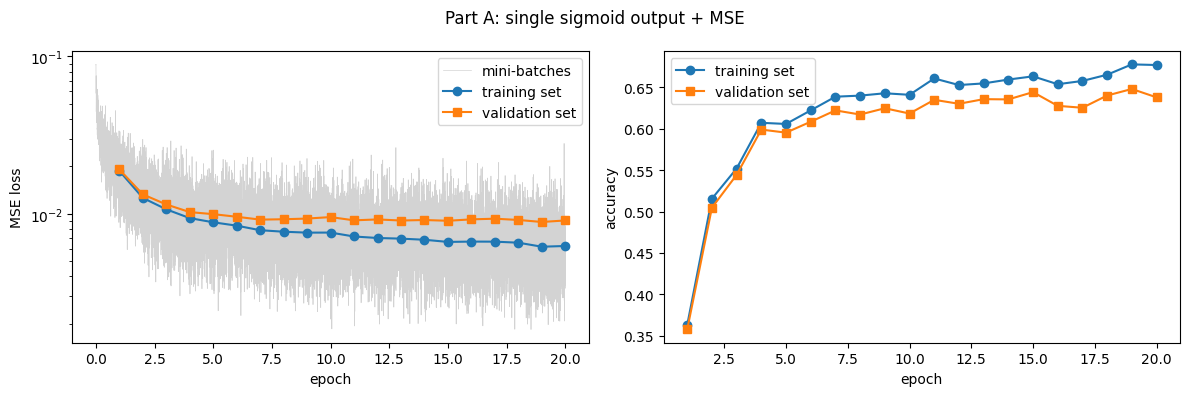

In [20]:
def plot_history(hist, loss_name, title):
    n_ep = len(hist["train loss"])
    epochs = np.arange(1, n_ep + 1)
    batch_x = np.arange(1, len(hist["batch loss"]) + 1) / (len(hist["batch loss"]) / n_ep)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(batch_x, hist["batch loss"], color="lightgrey", lw=0.5, label="mini-batches")
    axes[0].plot(epochs, hist["train loss"], "o-", label="training set")
    axes[0].plot(epochs, hist["val loss"], "s-", label="validation set")
    axes[0].set_yscale("log"); axes[0].set_ylabel(loss_name)
    axes[1].plot(epochs, hist["train acc"], "o-", label="training set")
    axes[1].plot(epochs, hist["val acc"], "s-", label="validation set")
    axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend()
    fig.suptitle(title); fig.tight_layout(); plt.show()

plot_history(hist_reg, "MSE loss", "Single sigmoid output and MSE")

The network learns, but slowly and not far: the validation accuracy rises from about $9\%$ before training and $36\%$ after one epoch to about $60\%$ after four epochs and then creeps up to
about $64\%$ after twenty. The loss on the validation set flattens after about seven epochs, while the training loss continues to decrease slightly:
the small hidden layer cannot do much better with this formulation of the task. The accuracy curve is jagged: a small change of the parameters can push many
outputs across a rounding boundary $k\pm0.5$ at once.

### 5.6 Confusion matrices (Box 2.11)
The **confusion matrix** $C$ counts, for every pair (true digit $i$, predicted digit $j$), how many images of digit $i$ (in a given set) were predicted as $j$.
We show it for all three sets: training (the data the parameters were fitted to), validation (used during training to monitor the model) and test
(used only now). Each row is normalised to sum to one, so $C_{ij}$ is the fraction of images of digit $i$ that were classified as $j$; the diagonal element $C_{ii}$ is
the fraction of digit $i$ recognised correctly. The mean of the diagonal is the accuracy averaged over classes (Box 2.11); since the MNIST classes are
nearly balanced it is almost equal to the plain accuracy.

The matrix is built with one `bincount`: the pair $(i, j)$ is encoded as the single number $10i + j \in\{0,\dots,99\}$, the occurrences are counted and
arranged as a $10\times10$ matrix.

accuracy (regression):  training 0.677   validation 0.638   test 0.652


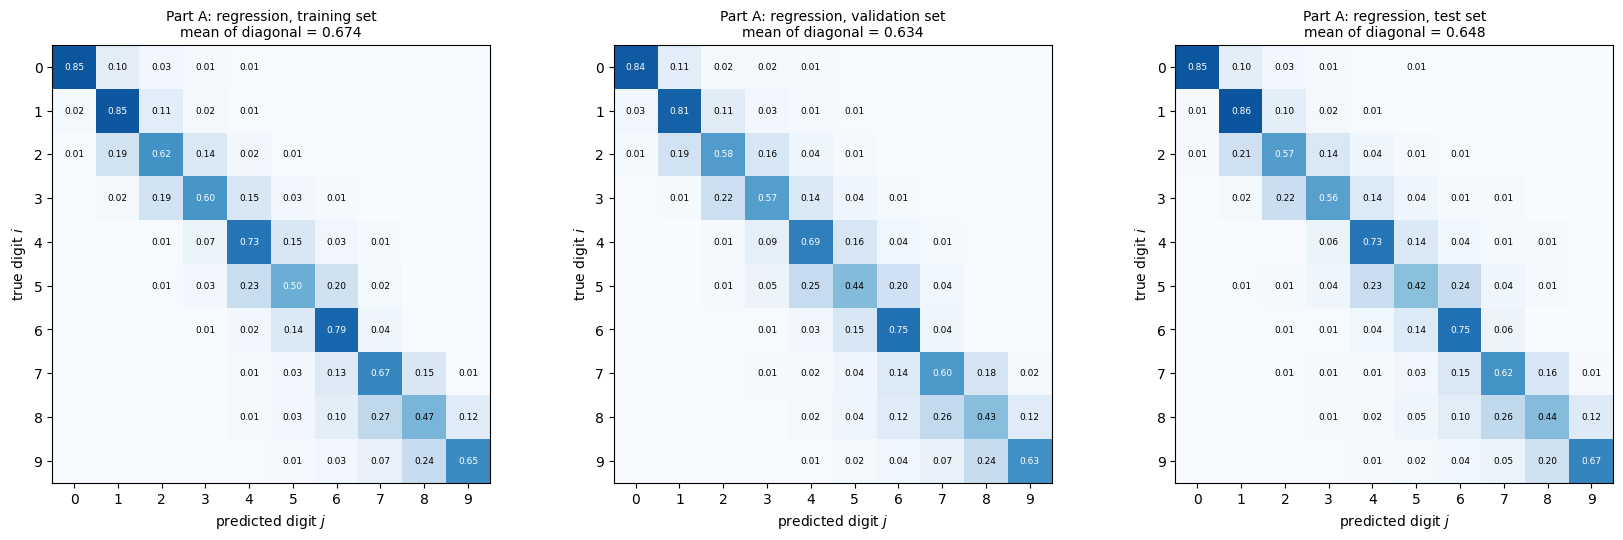

In [21]:
def confusion_matrix(y_true, y_pred, k=10):
    C = torch.bincount(k * y_true + y_pred, minlength=k * k).reshape(k, k).float()
    return C / C.sum(dim=1, keepdim=True)              # each row (true class) sums to 1

def plot_confusion(ax, C, title):
    im = ax.imshow(C, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if C[i, j] >= 0.005:
                ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if C[i, j] > 0.5 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("predicted digit $j$"); ax.set_ylabel("true digit $i$")
    ax.set_title(f"{title}\nmean of diagonal = {C.diagonal().mean():.3f}", fontsize=10)
    return im

with torch.no_grad():
    y_bar_tr = model_reg(X_tr).squeeze(1)
    y_bar_va = model_reg(X_va).squeeze(1)
    y_bar_te = model_reg(X_te).squeeze(1)
pred_reg_tr = predict_digit_regression(y_bar_tr)
pred_reg_va = predict_digit_regression(y_bar_va)
pred_reg_te = predict_digit_regression(y_bar_te)
acc_reg_te = (pred_reg_te == y_te).float().mean().item()
C_reg_tr = confusion_matrix(y_tr, pred_reg_tr)
C_reg_va = confusion_matrix(y_va, pred_reg_va)
C_reg = confusion_matrix(y_te, pred_reg_te)
print(f"accuracy (regression):  training {(pred_reg_tr == y_tr).float().mean():.3f}"
      f"   validation {(pred_reg_va == y_va).float().mean():.3f}   test {acc_reg_te:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
plot_confusion(axes[0], C_reg_tr, "Model A (regression), training set")
plot_confusion(axes[1], C_reg_va, "Model A (regression), validation set")
plot_confusion(axes[2], C_reg, "Model A (regression), test set")
fig.tight_layout(); plt.show()

The test accuracy is about $65\%$, higher than the $56\%$ reported in the chapter, which uses full-batch gradient descent instead of Adam with mini-batches (see Exercise 5). The three matrices look almost the same. Training and test accuracies differ by only about 2–3 points, so overfitting is mild; validation and test agree, so the validation set,
which we watched during training, was a reliable estimate of the performance on new data. The model is
limited by the task as posed. The confusion matrix shows the characteristic pattern of the regression: the errors form **bands next to the
diagonal**. A $5$ is predicted as $4$ or $6$ in almost half of the cases, an $8$ as $7$ or $9$ and a $2$ as $1$ or $3$ in more than a third. Confusions between digits of similar
*shape* but distant *value* (such as $4$ and $9$) do not appear as such.

The continuous output shows why. For every true digit we plot the distribution of $10\,\bar y$ over the test images (a *violin plot*: the width is the
histogram of the values). The dashed horizontal lines are the rounding boundaries $k\pm 0.5$; an image is classified correctly when its value lies in the
band around its own digit.

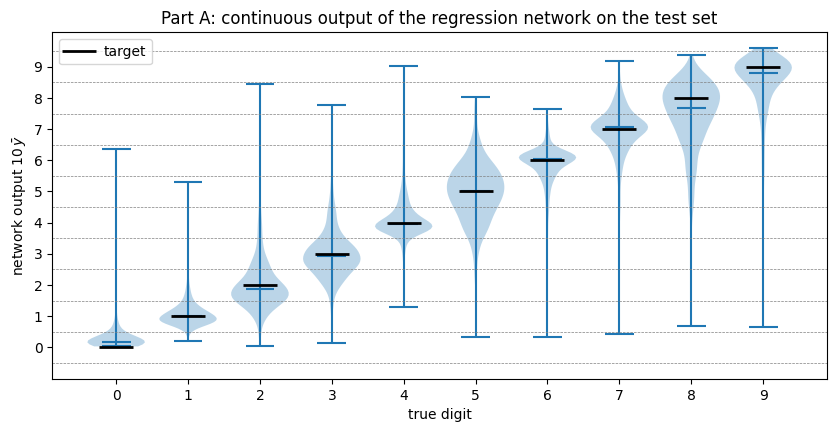

wrong predictions: 3480 of 10000;  of these off by exactly 1: 76%


In [22]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.violinplot([10 * y_bar_te[y_te == k].numpy() for k in range(10)], positions=range(10), widths=0.8, showmedians=True)
for b in np.arange(-0.5, 10, 1):
    ax.axhline(b, color="grey", lw=0.5, ls="--")
ax.plot(range(10), range(10), "k_", ms=25, mew=2, label="target")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("true digit"); ax.set_ylabel(r"network output $10\,\bar y$"); ax.legend(loc="upper left")
ax.set_title("Continuous output of the regression network on the test set")
plt.show()

off = (pred_reg_te - y_te).abs()[pred_reg_te != y_te]
print(f"wrong predictions: {len(off)} of {len(y_te)};  of these off by exactly 1: {(off == 1).float().mean():.0%}")

The output for each digit is centred near the target, but the distributions are wide, about one unit for most digits, and have long tails (the blue horizontal
bars mark the minimum, median and maximum; the black bars the targets). Everything that leaks across a dashed line becomes a wrong digit, and leaking across one line is far more likely than across
several: about three quarters of the wrong predictions are off by exactly one. $0$, $1$ and $6$ are narrowest; $5$ and $8$, which sit in the middle of
many other digits on the number line, are the widest and the worst recognised.

<hr/>
## 6. Ten outputs, softmax and categorical cross-entropy

### 6.1 One-hot encoding, softmax and the cross-entropy
In model B the network returns, instead of one number, $K = 10$ numbers $z_0,\dots,z_9$ (the *logits*), one per class. The **softmax**
$$q_k = \mathrm{SoftMax}(\mathbf z)_k = \frac{e^{z_k}}{\sum_{j=0}^{9} e^{z_j}}$$
turns them into a probability distribution $\mathbf q$: $q_k > 0$ and $\sum_k q_k = 1$. $q_k$ is read as the probability, according to the network, that the
image shows digit $k$. The predicted digit is the most probable one, $\arg\max_k q_k$.

The label $y$ is written as a **one-hot** vector $\mathbf p$ with $p_k = \delta_{k,y}$ (Box 2.7): the "true" distribution, all probability on the correct
class. Two distributions are compared with the Kullback–Leibler divergence (Box 2.8),
$$\mathrm{KL}(\mathbf p\,\|\,\mathbf q) = \sum_k p_k\log\frac{p_k}{q_k} = \underbrace{\sum_k p_k\log p_k}_{-\,\mathcal H(\mathbf p)\ \text{(no }\boldsymbol\theta\text{)}}\;\underbrace{-\sum_k p_k\log q_k}_{\mathcal L_{\rm ce}} .$$
(Here and below $\log$ denotes the natural logarithm.) Only the second term depends on the network, so the loss is the **categorical cross-entropy**, averaged over the batch of $B$ images. For a one-hot $\mathbf p$ only the
term of the true class survives:
$$\mathcal L_{\rm ce} = -\frac1B\sum_{i=1}^{B}\sum_{k=0}^{9} p_{ik}\log q_{ik} = -\frac1B\sum_{i=1}^{B}\log q_{i,y_i} .$$
It is $0$ if the network gives probability $1$ to the true class and grows without bound as that probability goes to $0$.

In PyTorch, `nn.CrossEntropyLoss` takes the **logits** of shape `(B, 10)` and the labels as integers of shape `(B,)`. It applies the softmax itself (in a
numerically stable form, via $\log\sum_j e^{z_j}$), so the model must **not** end with a softmax layer. On random logits the formula
above, written out with one-hot vectors, gives the same number.

In [23]:
torch.manual_seed(0)
z = torch.randn(5, 10)                                  # logits for a batch of 5 images
y5 = y_tr[:5]                                           # their true labels

q = torch.softmax(z, dim=1)                             # probabilities, each row sums to 1
p = nn.functional.one_hot(y5, num_classes=10).float()   # one-hot labels, shape (5, 10)
print("labels:", y5.tolist())
print("one-hot p:\n", p.int())
print("row sums of q:", q.sum(dim=1).tolist())

ce_by_hand = -(p * torch.log(q)).sum(dim=1).mean()
ce_torch = nn.CrossEntropyLoss()(z, y5)
print(f"cross-entropy from the formula: {ce_by_hand:.6f}   nn.CrossEntropyLoss: {ce_torch:.6f}")

labels: [1, 7, 1, 0, 9]
one-hot p:
 tensor([[0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]], dtype=torch.int32)
row sums of q: [0.9999999403953552, 1.0, 1.0, 1.0000001192092896, 0.9999998807907104]
cross-entropy by hand: 3.534212   nn.CrossEntropyLoss: 3.534213


### 6.2 Ten-output network
The hidden layer is exactly that of model A. Only the output layer changes: $10$ nodes instead of $1$, and no sigmoid (the softmax is inside the loss).

In [24]:
def make_classification_model():
    return nn.Sequential(
        nn.Linear(784, N_HIDDEN), nn.Sigmoid(),      # hidden layer   (as in model A)
        nn.Linear(N_HIDDEN, 10),                     # TEN output nodes: logits z_0 ... z_9
    )

torch.manual_seed(0)
model_ce = make_classification_model()
print(model_ce)
print("parameters:", sum(p.numel() for p in model_ce.parameters()),
      "  (model A:", sum(p.numel() for p in model_reg.parameters()), ";  difference 9 * (N_HIDDEN + 1) =", 9 * (N_HIDDEN + 1), ")")

Sequential(
  (0): Linear(in_features=784, out_features=21, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=21, out_features=10, bias=True)
)
parameters: 16705   (Part A: 16507 ;  difference 9 * (N_HIDDEN + 1) = 198 )


An untrained network gives roughly equal probabilities $q_k\approx 1/10$ to all classes, so the cross-entropy should start near $-\log(1/10) = \log 10 \approx 2.30$:

In [25]:
ce = nn.CrossEntropyLoss()

def evaluate_classification(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)                               # shape (N, 10)
        loss = ce(logits, y).item()
        acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc

loss0, acc0 = evaluate_classification(model_ce, X_va, y_va)
print(f"untrained: cross-entropy {loss0:.3f} (ln 10 = {np.log(10):.3f}),  accuracy {acc0:.3f}")

untrained: cross-entropy 2.356 (ln 10 = 2.303),  accuracy 0.072


### 6.3 Training loop with the cross-entropy
The loop is the same as for model A with three differences: the batches come from a `DataLoader` as in Section 4.2, the target is the integer label itself, and the
loss is the cross-entropy of the $10$ logits. Optimiser, learning rate, batch size and number of epochs are the same as for model A.

In [26]:
torch.manual_seed(0)
model_ce = make_classification_model()
optimizer = torch.optim.Adam(model_ce.parameters(), lr=1e-3)
n_epochs, batch_size = 20, 64
loader_tr = DataLoader(MNISTDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True,
                       generator=torch.Generator().manual_seed(1))
hist_ce = {"batch loss": [], "train loss": [], "val loss": [], "train acc": [], "val acc": []}

t_start = time.perf_counter()
for epoch in range(1, n_epochs + 1):
    model_ce.train()
    for xb, yb in loader_tr:                             # the DataLoader shuffles and batches
        logits = model_ce(xb)                            # forward pass, shape (B, 10)
        loss = ce(logits, yb)                            # target: integer labels, shape (B,)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        hist_ce["batch loss"].append(loss.item())

    tr_loss, tr_acc = evaluate_classification(model_ce, X_tr, y_tr)
    va_loss, va_acc = evaluate_classification(model_ce, X_va, y_va)
    for key, v in zip(["train loss", "train acc", "val loss", "val acc"], [tr_loss, tr_acc, va_loss, va_acc]):
        hist_ce[key].append(v)
    if epoch == 1 or epoch % 2 == 0:
        print(f"epoch {epoch:2d}:  CE train {tr_loss:.4f}  val {va_loss:.4f}   accuracy train {tr_acc:.3f}  val {va_acc:.3f}")
print(f"training took {time.perf_counter() - t_start:.0f} s")

epoch  1:  CE train 0.4569  val 0.4661   accuracy train 0.901  val 0.896


epoch  2:  CE train 0.3078  val 0.3221   accuracy train 0.922  val 0.917


epoch  4:  CE train 0.2257  val 0.2510   accuracy train 0.939  val 0.932


epoch  6:  CE train 0.1886  val 0.2199   accuracy train 0.948  val 0.938


epoch  8:  CE train 0.1670  val 0.2047   accuracy train 0.954  val 0.941


...

epoch 12:  CE train 0.1396  val 0.1913   accuracy train 0.960  val 0.942


epoch 14:  CE train 0.1281  val 0.1873   accuracy train 0.965  val 0.945


epoch 16:  CE train 0.1246  val 0.1899   accuracy train 0.965  val 0.944


epoch 18:  CE train 0.1125  val 0.1824   accuracy train 0.969  val 0.945


epoch 20:  CE train 0.1065  val 0.1815   accuracy train 0.970  val 0.946
training took 13 s


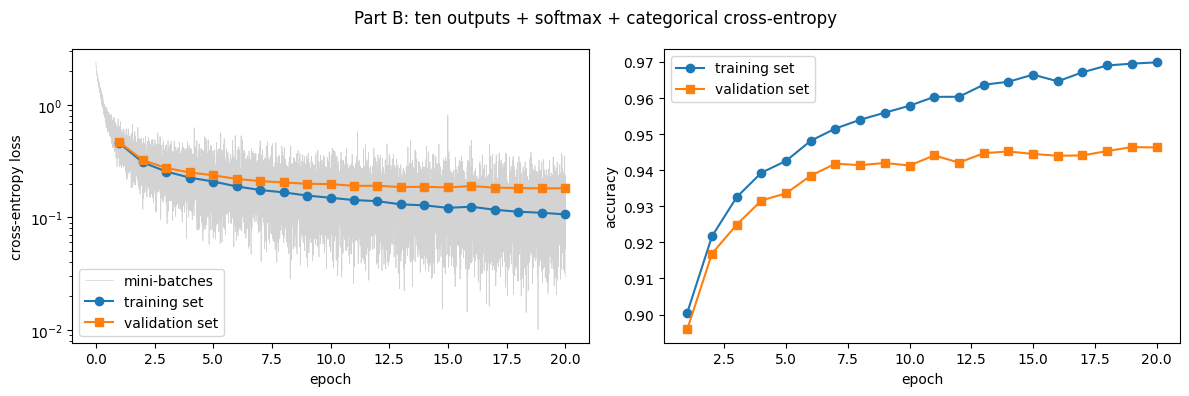

In [27]:
plot_history(hist_ce, "cross-entropy loss", "Ten outputs, softmax and cross-entropy")

The same network, the same optimiser, the same data: after a single epoch the validation accuracy is already about $90\%$, far above anything the
regression reached in twenty epochs. It then rises slowly to about $94.6\%$. Training and validation curves stay close (training accuracy $97\%$), so this
small network barely overfits.

accuracy (cross-entropy):  training 0.970   validation 0.946   test 0.948


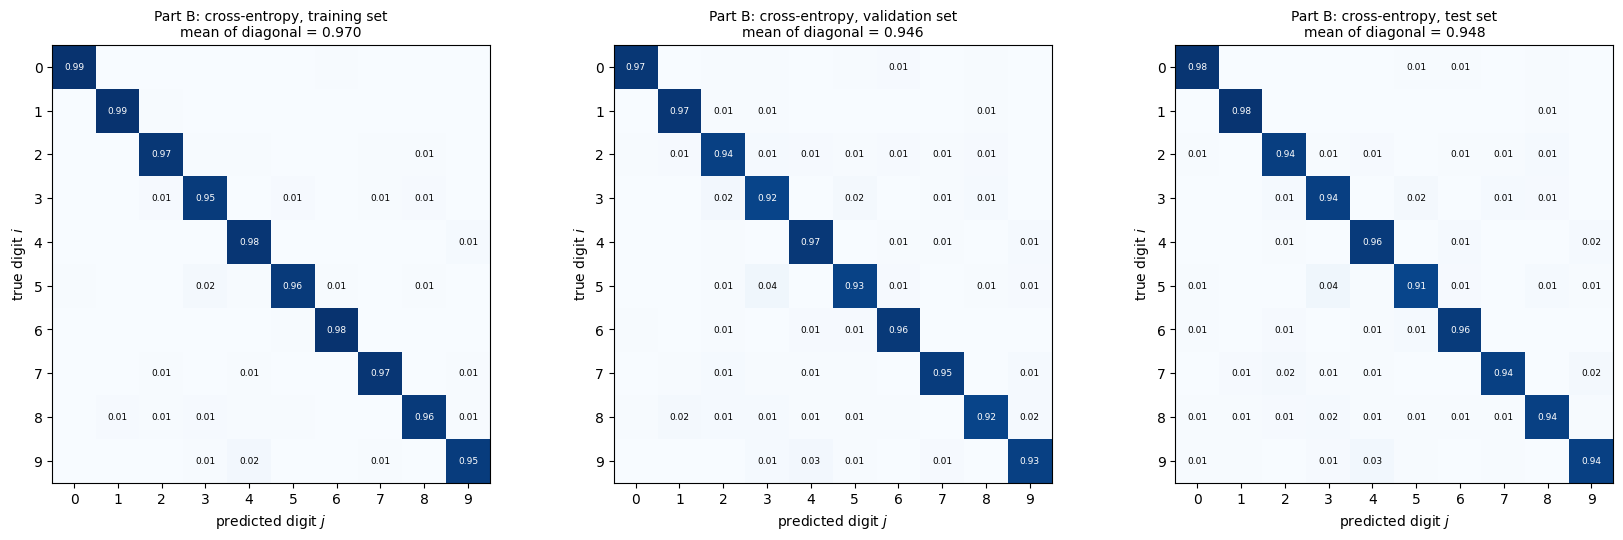

In [28]:
with torch.no_grad():
    pred_ce_tr = model_ce(X_tr).argmax(dim=1)
    pred_ce_va = model_ce(X_va).argmax(dim=1)
    logits_te = model_ce(X_te)
q_te = torch.softmax(logits_te, dim=1)                   # probabilities, shape (10000, 10)
pred_ce_te = q_te.argmax(dim=1)
acc_ce_te = (pred_ce_te == y_te).float().mean().item()
C_ce_tr = confusion_matrix(y_tr, pred_ce_tr)
C_ce_va = confusion_matrix(y_va, pred_ce_va)
C_ce = confusion_matrix(y_te, pred_ce_te)
print(f"accuracy (cross-entropy):  training {(pred_ce_tr == y_tr).float().mean():.3f}"
      f"   validation {(pred_ce_va == y_va).float().mean():.3f}   test {acc_ce_te:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
plot_confusion(axes[0], C_ce_tr, "Model B (cross-entropy), training set")
plot_confusion(axes[1], C_ce_va, "Model B (cross-entropy), validation set")
plot_confusion(axes[2], C_ce, "Model B (cross-entropy), test set")
fig.tight_layout(); plt.show()

The test accuracy is about $95\%$ (the chapter: $95\%$), with about $500$ misclassified images instead of about $3\,500$. The diagonal is above $0.9$ for
every digit, on all three sets. The few off-diagonal entries no longer follow the number line; they follow the shapes
($4\to9$, $5\to3$, $7\to2$ and $7\to9$).

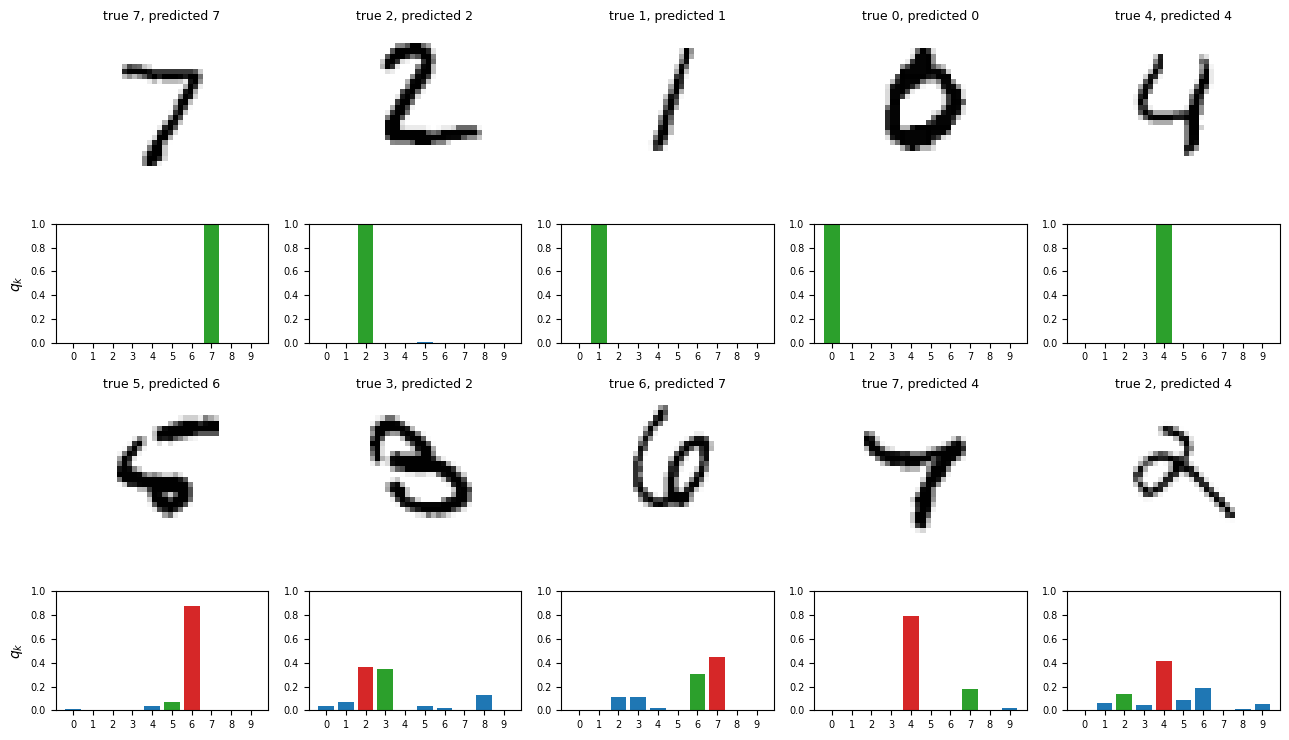

In [29]:
correct = torch.nonzero(pred_ce_te == y_te)[:, 0][:5]
wrong = torch.nonzero(pred_ce_te != y_te)[:, 0][:5]
fig, axes = plt.subplots(4, 5, figsize=(13, 7.5), gridspec_kw={"height_ratios": [1.2, 1, 1.2, 1]})
for row, chosen in [(0, correct), (2, wrong)]:
    for col, n in enumerate(chosen):
        axes[row, col].imshow(X_te_img[n], cmap="gray_r"); axes[row, col].axis("off")
        axes[row, col].set_title(f"true {y_te[n].item()}, predicted {pred_ce_te[n].item()}", fontsize=9)
        colors = ["tab:blue"] * 10
        colors[pred_ce_te[n]] = "tab:red"
        colors[y_te[n]] = "tab:green"
        axes[row + 1, col].bar(range(10), q_te[n].numpy(), color=colors)
        axes[row + 1, col].set_xticks(range(10)); axes[row + 1, col].set_ylim(0, 1)
        axes[row + 1, col].tick_params(labelsize=7)
axes[1, 0].set_ylabel("$q_k$"); axes[3, 0].set_ylabel("$q_k$")
fig.tight_layout(); plt.show()

For correctly classified images the network is nearly certain (one bar close to $1$). Among the mistakes, some are confident ($5$ read as $6$ with
probability $0.88$, an image that is ambiguous to a human, too), others show the doubt explicitly: for the $3$ read as $2$ the true class receives almost the
same probability as the prediction. The regression model cannot express such doubt: it returns one number.

<hr/>
## 7. Output layer and loss

### 7.1 Comparison of the two models
Both networks have the same hidden layer, the same optimiser, learning rate, batch size and number of epochs. They differ only in the output layer and the
loss. The figure shows the training and validation accuracies of both models against the epoch next to their test confusion matrices, and the
printed table gives the test accuracy and the number of misclassified test images.

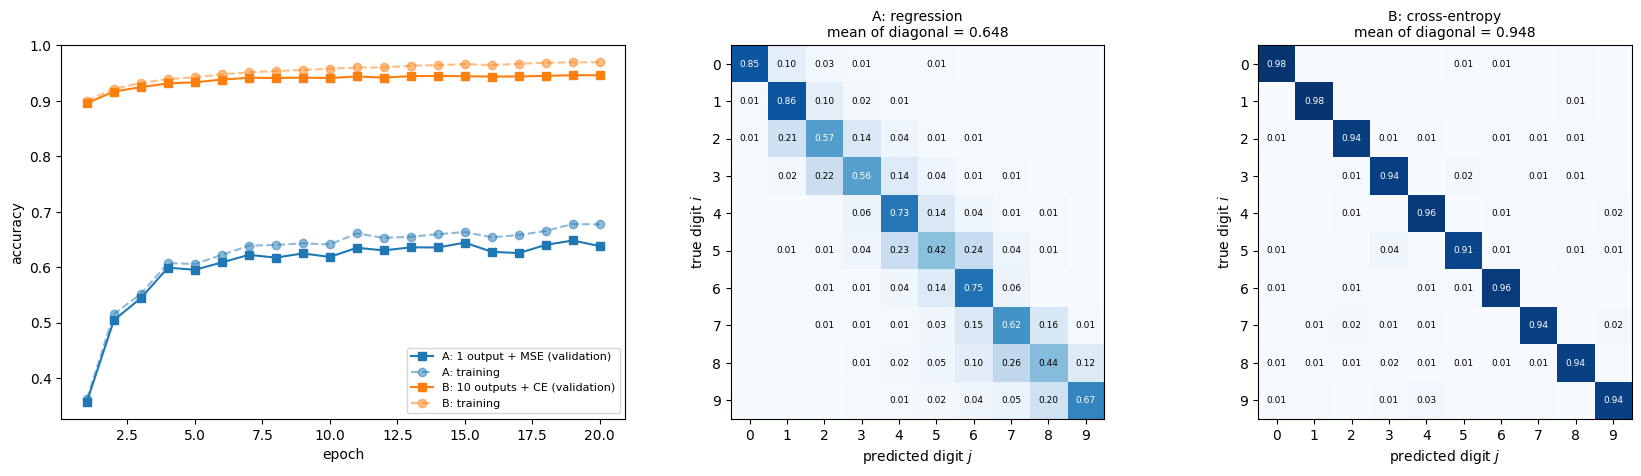

                              regression (A)  cross-entropy (B)
test accuracy                          0.652              0.948
misclassified test images               3480                516


In [30]:
epochs = np.arange(1, n_epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axes[0].plot(epochs, hist_reg["val acc"], "s-", label="A: 1 output + MSE (validation)")
axes[0].plot(epochs, hist_reg["train acc"], "o--", color="tab:blue", alpha=0.5, label="A: training")
axes[0].plot(epochs, hist_ce["val acc"], "s-", label="B: 10 outputs + CE (validation)")
axes[0].plot(epochs, hist_ce["train acc"], "o--", color="tab:orange", alpha=0.5, label="B: training")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy"); axes[0].legend(fontsize=8)
plot_confusion(axes[1], C_reg, "A: regression")
plot_confusion(axes[2], C_ce, "B: cross-entropy")
fig.tight_layout(); plt.show()

print(f"{'':28s} {'regression (A)':>15s} {'cross-entropy (B)':>18s}")
print(f"{'test accuracy':28s} {acc_reg_te:15.3f} {acc_ce_te:18.3f}")
print(f"{'misclassified test images':28s} {(pred_reg_te != y_te).sum().item():15d} {(pred_ce_te != y_te).sum().item():18d}")

This is the central result of the notebook. **With the same hidden layer, data and training, the single-output regression reaches about $65\%$ test accuracy and the ten-output
cross-entropy network about $95\%$**, with about seven times fewer errors. The difference comes from how the task is posed, that is, from the output
layer and the loss together; Exercise 2 shows that the ten outputs account for most of the gain. Model B is better in every epoch: after one epoch it is already far beyond the best value model A ever reaches.
The confusion matrices show two different kinds of errors: bands along the diagonal (A: neighbouring *values*) versus rare, scattered errors (B: similar *shapes*).

test images on which model B hesitates between two distant digits: 248


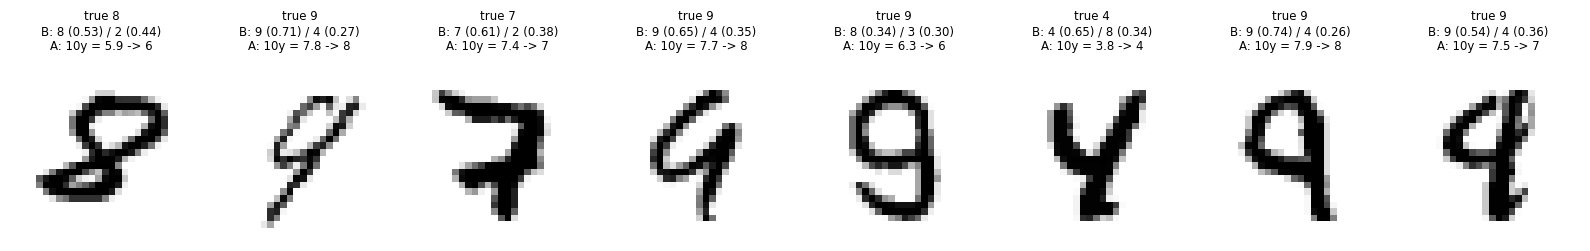

fraction of these images where A's output is more than 1 away from both candidate digits: 60%
mean |A's output - midpoint of the two candidates|: 1.42


In [31]:
top2 = q_te.topk(2, dim=1)                                # two largest probabilities and their digits
a, b = top2.indices[:, 0], top2.indices[:, 1]
doubtful = torch.nonzero((top2.values[:, 1] > 0.25) & ((a - b).abs() >= 3))[:, 0]
print("test images on which model B hesitates between two distant digits:", len(doubtful))

show = doubtful[:8]
fig, axes = plt.subplots(1, len(show), figsize=(2 * len(show), 2.9))
for ax, n in zip(np.atleast_1d(axes), show):
    ax.imshow(X_te_img[n], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"true {y_te[n].item()}\nB: {a[n].item()} ({q_te[n, a[n]]:.2f}) / {b[n].item()} ({q_te[n, b[n]]:.2f})\n"
                 f"A: 10y = {10 * y_bar_te[n]:.1f} -> {pred_reg_te[n].item()}", fontsize=8.5)
fig.tight_layout(); plt.show()

mid = (a[doubtful] + b[doubtful]).float() / 2
between = ((10 * y_bar_te[doubtful] - a[doubtful]).abs() > 1) & ((10 * y_bar_te[doubtful] - b[doubtful]).abs() > 1)
print(f"fraction of these images where A's output is more than 1 away from both candidate digits: {between.float().mean():.0%}")
print(f"mean |A's output - midpoint of the two candidates|: {(10 * y_bar_te[doubtful] - mid).abs().mean():.2f}")

In these hesitant cases the regression output tends to land **between** the two candidate digits: for about $60\%$ of the images it is more than $1$ away
from both of them. For example, an $8$ that model B reads as $8$ ($0.53$) or $2$ ($0.44$) gets $10\bar y\approx5.9$ from model A, which rounds to $6$,
a digit nobody would read in it. This is exactly what the MSE asks for: when the network cannot tell whether the target is $0.2$ or $0.8$, the value
minimising the expected squared error lies in between.

The single-output regression must fit a function that jumps between the values $0, 0.1, \dots, 0.9$ in an arbitrary order of shapes; the rounding
then turns every small error into a neighbouring digit, and every hesitation into an average. The ten-output network treats the classes as unordered
categories and returns a probability for each.

### 7.2 Architectures of models A and B
The comparison rests on the fact that the two networks differ only in their output layer. Drawings of both networks make this visible at a glance,
and a table of the layers shows where the parameters sit.

The function below is the drawing function used for network diagrams throughout the course. It draws a dense network as columns of
circles, one column per layer and one circle per neuron, and joins every circle with every circle of the next column by a thin grey line, one
line per weight. The height of a column grows with the logarithm of the layer size, so that a wide layer looks taller than a narrow one and a network
that compresses its input visibly narrows. A layer with more neurons than `max_nodes` is drawn with its first and last few neurons and a vertical
ellipsis in between; its true size is always written under the column. The colours follow one convention in all notebooks: grey for the data at the
input and at the output, blue for hidden layers, orange for a latent (bottleneck) layer and green for an additional input such as a class label.

To draw your own network, pass the list of layer sizes from the input to the output, for example `draw_network([784, 128, 64, 10])`, and, if you
wish, a list of names (`labels`) and of colours (`colors`) with one entry per column. An entry of `layer_sizes` can itself be a list, such as
`[16, 16]`, which stacks two blocks in one column; `groups` draws a bracket with a name above a range of columns, and `no_input` lists blocks that
receive no edges from the previous column. The function returns the matplotlib axes, so the figure can be changed further or saved with
`ax.figure.savefig(...)`. It needs only NumPy and matplotlib and therefore also runs in Colab. The comments in the code explain each step
(node positions, the truncation of large layers, the edges, the labels and the brackets), so that the function can be adapted to other diagrams.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names written under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always written in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


Both networks start with the 784 standardised pixel values and the hidden layer of $N^{(1)} = 21$ sigmoid nodes (drawn with the ellipsis,
since 21 is more than ten). Model A ends in one sigmoid output, the value $\bar y$ that is multiplied by ten and rounded; model B ends in ten
logits, one per digit, which the softmax inside the loss turns into probabilities.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
draw_network([784, N_HIDDEN, 1], labels=["input", "hidden, sigmoid", "output, sigmoid"], ax=axes[0])
axes[0].set_title("model A: regression", fontsize=13)
draw_network([784, N_HIDDEN, 10], labels=["input", "hidden, sigmoid", "logits"], ax=axes[1])
axes[1].set_title("model B: cross-entropy", fontsize=13)
plt.show()

The library `torchinfo` prints a table of the layers. `torchinfo.summary(model, input_size=...)` passes a batch of zeros of the given shape
through the model and records, for every layer, the shape of its output and the number of its parameters; the lines at the bottom give the totals
and an estimate of the memory needed. The first number of `input_size` is the batch size: it appears as the first dimension of every output
shape and does not change the parameter counts. The library `torchview` passes the same kind of batch through the model and draws the layers as a
graph in which every box is one layer with the shapes of its input and output; with `expand_nested=True` layers that sit inside a container are
drawn inside a frame. The graph is rendered by the program Graphviz to a PNG (Portable Network Graphics) file in the folder `figures`.

The three views serve different purposes. The neuron-level drawing explains what a dense layer is but is practical only for small dense networks.
The `torchinfo` table is the quickest check of shapes and parameter counts and the first thing to print when a model raises a shape error. The
`torchview` graph shows how the layers are connected, which matters as soon as the data flow is not a single chain, for example with skip
connections or several inputs.

In [ ]:
import importlib.util, os, subprocess, sys
for package in ["torchinfo", "torchview"]:          # installed only if missing, e.g. in a fresh Colab session
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
import torchinfo
from torchview import draw_graph
from IPython.display import Image, display

for name, m in [("model A", model_reg), ("model B", model_ce)]:
    info = torchinfo.summary(m, input_size=(64, 784), verbose=0)   # one mini-batch of 64 image vectors
    print(name); print(info)
    print("parameters: torchinfo", info.total_params, "  our count", sum(p.numel() for p in m.parameters()), "\n")

In [ ]:
os.makedirs("figures", exist_ok=True)
graph = draw_graph(model_ce, input_size=(64, 784), expand_nested=True)
png = graph.visual_graph.render("figures/lab009_model_B_graph", format="png", cleanup=True)   # Graphviz writes the PNG file
display(Image(png))

The two tables agree with the counts printed in Sections 5.2 and 6.2: 16 507 parameters for model A and 16 705 for model B. The hidden
layer holds $784\cdot21 + 21 = 16\,485$ of them in both models, almost all; the output layers differ by $9\cdot(21 + 1) = 198$ parameters. The
large difference in accuracy therefore does not come from a larger network: model B has only about 1% more parameters. The graph of model B
shows the three layers of the `Sequential` with the shapes $(64, 784)\to(64, 21)\to(64, 21)\to(64, 10)$; the softmax does not appear, because it
is part of the loss function, not of the model.

<hr/>
## Summary

MNIST is distributed as four binary files in the IDX format: a short header (data type, number of dimensions, sizes) followed by one byte per pixel or
label. Ten lines of NumPy read them; the data loaders of libraries do nothing more. For a dense network the images are flattened to vectors of $784$
numbers and standardised with the mean and standard deviation of the **training** set only. The $60\,000$ training images are split at random into
training ($50\,000$) and validation ($10\,000$) sets, and the separate MNIST test file serves as the test set.

An epoch is one pass over a random permutation of the training set, cut into mini-batches; `Dataset` and `DataLoader` implement exactly this and are most
useful when the data do not fit into memory. The training loop performs, for every batch, the forward pass, the loss, `zero_grad`, `backward` and `step`,
and after every epoch evaluates the model on the training and validation sets without gradients.

The main message concerns regression against classification. With the same hidden layer, data and training, the single-output regression reaches about $65\%$ test accuracy and the ten-output cross-entropy network about $95\%$.
The difference comes from how the task is posed: the output layer and the loss together. One sigmoid output trained with the MSE on the rescaled digit imposes
an order and a distance on the classes that do not exist; its errors are mostly neighbouring digits and averages of two candidates. Ten outputs treat the
classes as categories; Exercise 2 shows that they account for most of the gain (ten sigmoid outputs with the MSE reach about $94\%$).

<hr/>
## Exercises

### Exercise 1 — Truncation instead of rounding
Evaluate the trained regression model `model_reg` on the test set with the prediction `(10 * y_bar).long()` (truncation, as Python's `int()`) instead of rounding.
How much accuracy is lost? Then train model A again (10 epochs suffice) with the targets $(y + 0.5)/10$ instead of $y/10$: for which
prediction rule (rounding or truncation) are these targets the natural choice, and do you recover the accuracy?

#### Solution

In [32]:
with torch.no_grad():
    y_bar = model_reg(X_te).squeeze(1)
acc_round = (predict_digit_regression(y_bar) == y_te).float().mean().item()
acc_trunc = ((10 * y_bar).long().clamp(0, 9) == y_te).float().mean().item()
print(f"targets y/10:        rounding {acc_round:.3f},  truncation {acc_trunc:.3f}")

# targets in the middle of the interval [y/10, (y+1)/10): truncation is then the natural rule
torch.manual_seed(0)
model_shift = make_regression_model()
opt = torch.optim.Adam(model_shift.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(1)
for epoch in range(10):
    for idx in batch_indices(len(X_tr), 64, generator=gen):
        loss = mse(model_shift(X_tr[idx]).squeeze(1), (y_tr[idx].float() + 0.5) / 10)
        opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    y_bar = model_shift(X_te).squeeze(1)
print(f"targets (y+0.5)/10:  truncation {((10 * y_bar).long().clamp(0, 9) == y_te).float().mean():.3f}"
      f",  rounding {(predict_digit_regression(y_bar) == y_te).float().mean():.3f}")

targets y/10:        rounding 0.652,  truncation 0.445


targets (y+0.5)/10:  truncation 0.631,  rounding 0.470


With targets $y/10$, an output slightly below the target (e.g. $2.97$ for a $3$) is truncated to the wrong digit: truncation drops the accuracy from about
$65\%$ to about $45\%$. With the shifted targets $(y + 0.5)/10$ the target sits in the middle of the interval $[y, y+1)$ that truncation maps to $y$, so
truncation is the right rule (and now rounding fails). After $10$ epochs the shifted model reaches about $63\%$ on the test set, comparable to model A after $10$ epochs
($62\%$ on the validation set). The rule turning the continuous output into a class must match the encoding of the targets.

### Exercise 2 — Ten outputs with the mean squared error
Is the improvement of model B due to the ten outputs or to the cross-entropy? Train the network of model B with ten **sigmoid** outputs and the **MSE** between
the outputs and the one-hot vectors $\mathbf p$ (predicted digit: the largest output). Use 10 epochs and compare the test accuracy with models A and B.

#### Solution

In [33]:
torch.manual_seed(0)
model_onehot_mse = nn.Sequential(nn.Linear(784, N_HIDDEN), nn.Sigmoid(), nn.Linear(N_HIDDEN, 10), nn.Sigmoid())
opt = torch.optim.Adam(model_onehot_mse.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(1)
for epoch in range(1, 11):
    for idx in batch_indices(len(X_tr), 64, generator=gen):
        p = nn.functional.one_hot(y_tr[idx], 10).float()
        loss = mse(model_onehot_mse(X_tr[idx]), p)
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch % 5 == 0:
        with torch.no_grad():
            acc = (model_onehot_mse(X_va).argmax(1) == y_va).float().mean().item()
        print(f"epoch {epoch:2d}: validation accuracy {acc:.3f}")
with torch.no_grad():
    acc_te = (model_onehot_mse(X_te).argmax(1) == y_te).float().mean().item()
print(f"test accuracy:  A (1 output, MSE) {acc_reg_te:.3f}   10 outputs + MSE {acc_te:.3f}   B (10 outputs, CE) {acc_ce_te:.3f}")

epoch  5: validation accuracy 0.922


epoch 10: validation accuracy 0.935
test accuracy:  A (1 output, MSE) 0.652   10 outputs + MSE 0.938   B (10 outputs, CE) 0.948


Most of the gain comes from the **ten outputs**: with one-hot targets there is no artificial order of the classes, and even the MSE gives about $94\%$, close
to the cross-entropy ($95\%$). The cross-entropy still has two advantages: its outputs form a probability distribution with a clear interpretation, and its
gradient does not vanish when an output is confidently wrong (for a sigmoid output with MSE the gradient contains $\sigma(1-\sigma)$, which is tiny when the
sigmoid saturates at the wrong end), so it typically learns faster.

### Exercise 3 — Batch size
Train model B for 5 epochs with batch sizes $16$, $64$, $512$ and $50\,000$ (full batch), always with Adam and learning rate $10^{-3}$.
Record the validation accuracy after 5 epochs, the number of parameter updates and the training time. Explain the result.

#### Solution

In [34]:
for bs in [16, 64, 512, 50_000]:
    torch.manual_seed(0)
    model = make_classification_model()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(1)
    n_updates, t0 = 0, time.perf_counter()
    for epoch in range(5):
        for idx in batch_indices(len(X_tr), bs, generator=gen):
            loss = ce(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            n_updates += 1
    _, acc = evaluate_classification(model, X_va, y_va)
    print(f"batch size {bs:6d}: {n_updates:6d} updates, {time.perf_counter() - t0:5.1f} s,  validation accuracy {acc:.3f}")

batch size     16:  15625 updates,   7.8 s,  validation accuracy 0.944


batch size     64:   3910 updates,   2.0 s,  validation accuracy 0.937


batch size    512:    490 updates,   0.4 s,  validation accuracy 0.897


batch size  50000:      5 updates,   0.2 s,  validation accuracy 0.360


All runs see the same number of images (5 epochs), but the number of parameter updates differs by a factor of $3\,000$. The full batch makes only $5$ updates and
is still close to guessing ($36\%$); batch size $512$ reaches about $90\%$. Batch sizes $16$ and $64$ give similar accuracy (about $94\%$), but $16$ is almost four
times slower: more Python overhead and smaller, less efficient matrix products per image. Batch sizes of a few tens to a few hundred are the usual compromise.
Giving the full batch the same *number of updates* as batch size $64$ would require thousands of epochs.

### Exercise 4 — Wider and deeper networks
The chapter's network is small: $784\cdot21 + 21 + 22 \approx 16\,500$ parameters. Train both models (regression and cross-entropy) for 10 epochs with the hidden
layers `[21]` (models A and B), `[128]` (one wider layer) and `[128, 64]` (two hidden layers), all with sigmoids, and compare the test accuracies.
Which of the two approaches profits more from a larger network? Does the conclusion of Section 7 change?

#### Solution

In [35]:
def make_mlp(hidden, n_out, sigmoid_output):
    layers, n_in = [], 784
    for n in hidden:                                     # hidden layers with sigmoids
        layers += [nn.Linear(n_in, n), nn.Sigmoid()]
        n_in = n
    layers.append(nn.Linear(n_in, n_out))
    if sigmoid_output:
        layers.append(nn.Sigmoid())
    return nn.Sequential(*layers)

def train_quick(model, kind, n_epochs=10):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(1)
    for epoch in range(n_epochs):
        for idx in batch_indices(len(X_tr), 64, generator=gen):
            if kind == "regression":
                loss = mse(model(X_tr[idx]).squeeze(1), y_tr[idx].float() / 10)
            else:
                loss = ce(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        if kind == "regression":
            return (predict_digit_regression(model(X_te).squeeze(1)) == y_te).float().mean().item()
        return (model(X_te).argmax(1) == y_te).float().mean().item()

print(f"{'hidden layers':14s} {'parameters':>11s} {'regression':>11s} {'cross-entropy':>14s}")
for hidden in [[21], [128], [128, 64]]:
    torch.manual_seed(0)
    m_reg = make_mlp(hidden, 1, sigmoid_output=True)
    torch.manual_seed(0)
    m_ce = make_mlp(hidden, 10, sigmoid_output=False)
    n_par = sum(p.numel() for p in m_reg.parameters())
    print(f"{str(hidden):14s} {n_par:11d} {train_quick(m_reg, 'regression'):11.3f} {train_quick(m_ce, 'classification'):14.3f}")

hidden layers   parameters  regression  cross-entropy


[21]                 16507       0.631          0.943


[128]               100609       0.733          0.972


[128, 64]           108801       0.799          0.973


Both approaches profit from a larger network, the regression much more (from $63\%$ to $80\%$ in 10 epochs) than the cross-entropy (from $94\%$ to $97\%$).
The gap shrinks but remains large: the cross-entropy with the chapter's tiny network ($16\,500$ parameters) is still far better than the regression with a
network almost seven times larger. A big network can partly compensate for a badly posed task, but it is cheaper to pose the task well.

### Exercise 5 — Full-batch gradient descent as in the chapter
The chapter trains the smallest version of model A: $784\to21\to1$, sigmoid everywhere, no bias in the output layer, loss $\frac{1}{2N}\sum_{i=1}^N(\bar y_i - y_i/10)^2$ with $N = 50\,000$ training images,
and **full-batch** gradient descent (all $50\,000$ training images in every step) with a large learning rate. Build this network with `nn.Sequential`
(`nn.Linear(21, 1, bias=False)` for the output), train it with `torch.optim.SGD` for 500 full-batch steps with $\eta = 50$, and plot the training and validation
accuracy against the step. This is the network of model A; only the optimisation differs. Compare the test accuracy with model A. Why is such a large learning rate needed?

#### Solution

training took 9 s


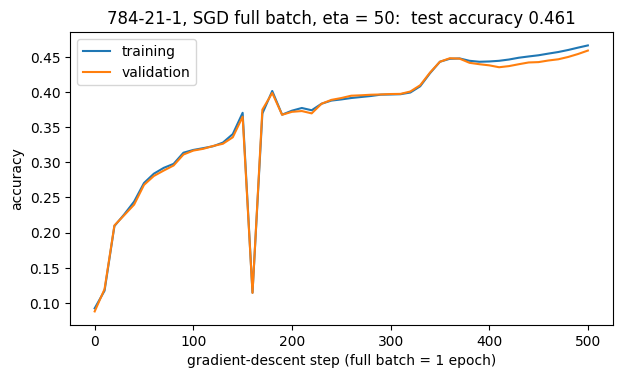

test accuracy: full-batch gradient descent 0.461   Part A (same network, Adam, mini-batches of 64) 0.652


In [36]:
torch.manual_seed(0)
model_book = nn.Sequential(nn.Linear(784, 21), nn.Sigmoid(), nn.Linear(21, 1, bias=False), nn.Sigmoid())
opt = torch.optim.SGD(model_book.parameters(), lr=50.0)
target_tr = y_tr.float() / 10
steps, acc_tr_book, acc_va_book = [], [], []
t0 = time.perf_counter()
for step in range(501):
    if step % 10 == 0:
        _, a_tr = evaluate_regression(model_book, X_tr, y_tr)
        _, a_va = evaluate_regression(model_book, X_va, y_va)
        steps.append(step); acc_tr_book.append(a_tr); acc_va_book.append(a_va)
    if step == 500:
        break
    model_book.train()
    loss = ((model_book(X_tr).squeeze(1) - target_tr)**2).mean() / 2    # ALL training images: full batch
    opt.zero_grad(); loss.backward(); opt.step()
print(f"training took {time.perf_counter() - t0:.0f} s")

_, acc_book_te = evaluate_regression(model_book, X_te, y_te)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(steps, acc_tr_book, label="training"); ax.plot(steps, acc_va_book, label="validation")
ax.set_xlabel("gradient-descent step (full batch = 1 epoch)"); ax.set_ylabel("accuracy"); ax.legend()
ax.set_title(f"784-21-1, SGD full batch, eta = 50:  test accuracy {acc_book_te:.3f}")
plt.show()
print(f"test accuracy: full-batch gradient descent {acc_book_te:.3f}   model A (same network, Adam, mini-batches of 64) {acc_reg_te:.3f}")

With full-batch gradient descent the same network reaches only about $46\%$ after $500$ steps, compared with $65\%$ for model A (the chapter reports $56\%$;
the exact number depends on the initialisation and the number of steps). The curve shows the price of a large learning rate: around step $160$ one step
overshoots, the accuracy collapses to $\approx 10\%$ and the network has to recover. A large $\eta$ is nevertheless needed because the gradient is tiny: by the
chain rule it contains factors $\sigma'(z) = \sigma(1-\sigma)\le 1/4$ (two factors for the hidden-layer weights, one for the output weights) and the small difference $\bar y - y/10$.
Model A makes $15\,640$ updates (20 epochs × 782 mini-batches) with Adam on mini-batches: about 30 times more updates than the $500$ full-batch steps, each with an adaptive step size.